In [17]:
#espero que essa merda funciione
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

--- REGRAS DE DECISAO DESSA PORRA ---
|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- sepal width (cm) <= 2.35
|   |   |   |--- class: 1
|   |   |--- sepal width (cm) >  2.35
|   |   |   |--- class: 1
|   |--- petal width (cm) >  1.55
|   |   |--- sepal length (cm) <= 6.10
|   |   |   |--- class: 2
|   |   |--- sepal length (cm) >  6.10
|   |   |   |--- class: 2



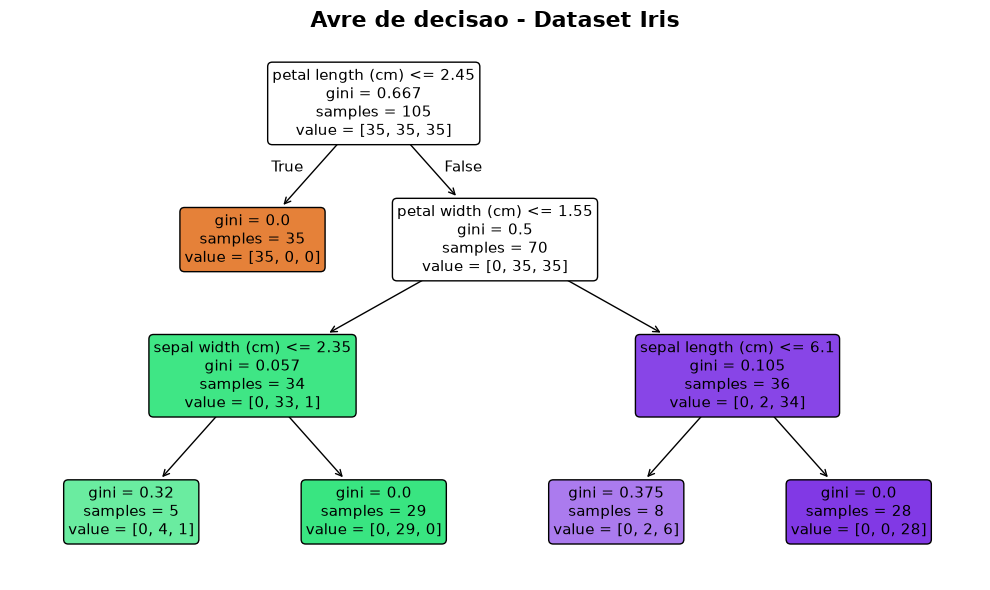

AttributeError: 'DecisionTreeClassifier' object has no attribute 'predic'

In [19]:
def treina_e_vizualiza_avre(X_treino, X_teste, Y_treino, Y_teste, 
                            feature_names, class_names, criterion='gini',
                            max_depth=3, min_samples_leaf=5):
    # CRIA ESSA PORRA DE CLASSIFICADOR
    clf= DecisionTreeClassifier(
            criterion=criterion,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=42
        )
     #setando os bang
    clf.fit(X_treino, Y_treino)
        
    regras = export_text(clf, feature_names=list(feature_names))
    print("--- REGRAS DE DECISAO DESSA PORRA ---")
    print(regras)
        #preparando as figura da avre
    fig, ax = plt.subplots(figsize=(10, 6),)
    plot_tree(
            clf,
            feature_names = feature_names,
            filled = True,
            rounded = True,
            fontsize = 11,
            ax = ax
        )
        
    plt.title("Avre de decisao - Dataset Iris", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig("arvore_decisao_iris.png", dpi=150)
    plt.show()
    plt.close()
        
    y_pred = clf.predic(X_teste)
    acc = accuracy_score(Y_teste, y_pred)
    return {
        "accuracy": round(float(acc), 4),
        "node_count: ": int(clf.tree_.node_count),
        "max_depth: ": int(clf.get_depth()),
        "n_leaves: ": int(clf.get_n_leaves())
    }
iris = load_iris()
X_tr, X_te, Y_tr, Y_te = train_test_split(iris.data, iris.target, test_size=0.3,
                                          random_state=42, stratify=iris.target,)
res = treina_e_vizualiza_avre(X_tr, X_te, Y_tr, Y_te,
                              feature_names=iris.feature_names, 
                              class_names=iris.target_names)
print("Resultado desse caralho de arvore filha da puta que só me da erro", res)